In [1]:
!pip install shap -q

from google.colab import drive
drive.mount('/content/drive')

import os, sys, json
os.chdir('/content/drive/MyDrive/network-intrusion-ml')
sys.path.append('/content/drive/MyDrive/network-intrusion-ml')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from scipy.stats import spearmanr

from src.utils import PROCESSED_DIR, METRIC_DIR, TABLE_DIR, FIG_DIR, MODEL_DIR, save_fig, save_table, RANDOM_STATE
from src.preprocessing import signed_log1p

sns.set_theme(style="whitegrid")

with open(METRIC_DIR / "label_mapping.json") as f:
    label_mapping = json.load(f)
class_names = [c for c, i in sorted(label_mapping.items(), key=lambda kv: kv[1])]
with open(MODEL_DIR / "model_features.json") as f:
    FEATURES = json.load(f)

bin_model = joblib.load(MODEL_DIR / "binary_model.pkl")
multi_model = joblib.load(MODEL_DIR / "multiclass_model.pkl")
xgb_bin = bin_model.named_steps["model"]
xgb_multi = multi_model.named_steps["model"]
print("Models loaded. Features:", len(FEATURES))

Mounted at /content/drive
Models loaded. Features: 48


[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/08_gain_importance.csv
[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/08_gain_importance.png


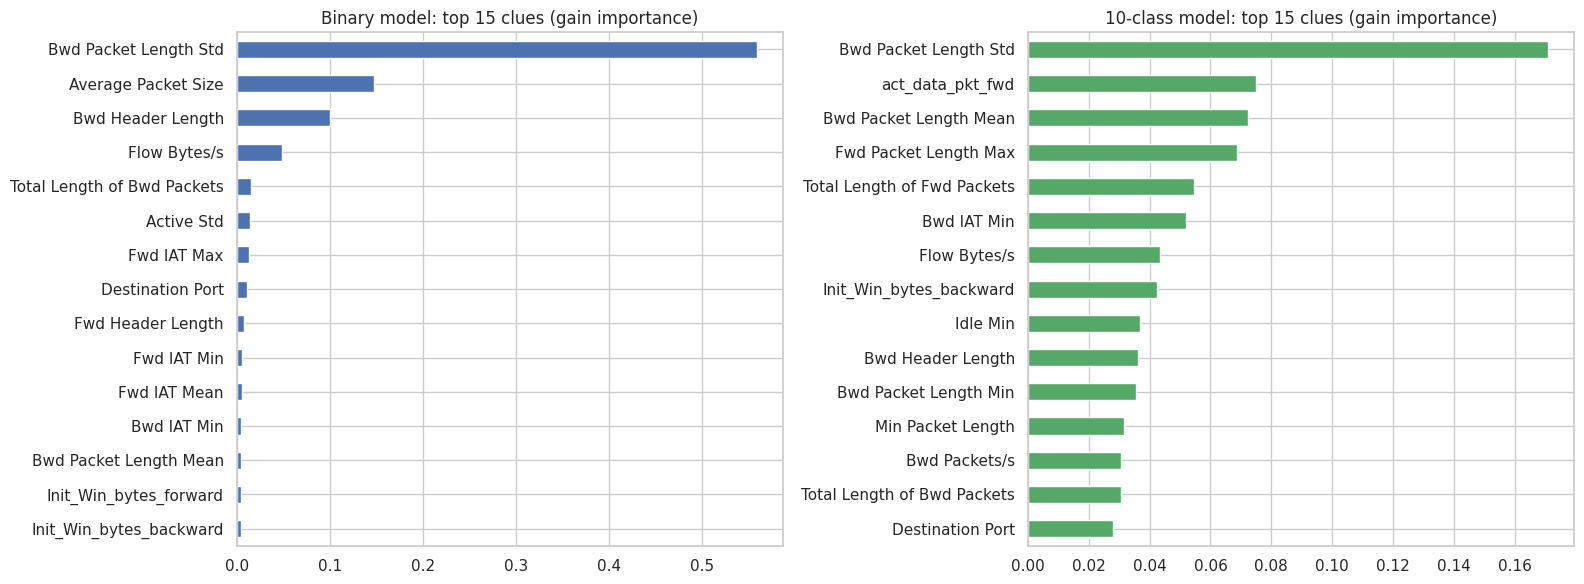

                             binary_gain  multiclass_gain
Bwd Packet Length Std             0.5589           0.1710
Average Packet Size               0.1469           0.0194
Bwd Header Length                 0.1003           0.0362
Flow Bytes/s                      0.0482           0.0432
Total Length of Bwd Packets       0.0155           0.0304
Active Std                        0.0140           0.0016
Fwd IAT Max                       0.0129           0.0009
Destination Port                  0.0107           0.0279
Fwd Header Length                 0.0070           0.0031
Fwd IAT Min                       0.0056           0.0064


In [2]:
def gain_importance(m):
    m.set_params(importance_type="gain")
    return pd.Series(m.feature_importances_, index=FEATURES)

imp_bin = gain_importance(xgb_bin)
imp_multi = gain_importance(xgb_multi)
imp_df = pd.DataFrame({"binary_gain": imp_bin, "multiclass_gain": imp_multi}).sort_values("binary_gain", ascending=False)
save_table(imp_df.round(5), "08_gain_importance")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
imp_bin.sort_values().tail(15).plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Binary model: top 15 clues (gain importance)")
imp_multi.sort_values().tail(15).plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("10-class model: top 15 clues (gain importance)")
save_fig("08_gain_importance")
plt.show()
print(imp_df.head(10).round(4).to_string())

In [3]:
test = pd.read_parquet(PROCESSED_DIR / "test.parquet", columns=FEATURES + ["Label_Group"])
y_t = test["Label_Group"].map(label_mapping).values
y_bin_t = (y_t != 0).astype(int)
pred_b = np.load(METRIC_DIR / "07_test_pred_binary.npy")

rng = np.random.default_rng(RANDOM_STATE)
idx = []
for c in range(len(class_names)):
    ids = np.where(y_t == c)[0]
    idx.extend(rng.choice(ids, size=min(400, len(ids)), replace=False))
idx = np.array(sorted(idx))

X_s = pd.DataFrame(signed_log1p(test.iloc[idx][FEATURES].values.astype("float32")), columns=FEATURES)
y_s = y_t[idx]
print("Sample size:", len(X_s))
print({class_names[k]: int(v) for k, v in zip(*np.unique(y_s, return_counts=True))})

# three single flows for the "explain one alert" plots
tp = np.where((y_bin_t == 1) & (pred_b == 1))[0]
fa = np.where((y_bin_t == 0) & (pred_b == 1))[0]
miss = np.where((y_bin_t == 1) & (pred_b == 0))[0]
local = {"Caught attack": int(rng.choice(tp)),
         "False alarm": int(rng.choice(fa)),
         "Missed attack": int(rng.choice(miss))}
X_loc = pd.DataFrame(signed_log1p(test.iloc[list(local.values())][FEATURES].values.astype("float32")),
                     columns=FEATURES)
loc_true = [class_names[y_t[i]] for i in local.values()]
loc_prob = bin_model.predict_proba(test.iloc[list(local.values())][FEATURES])[:, 1]
print("\nSingle flows:", dict(zip(local.keys(), loc_true)), "| model attack probability:", loc_prob.round(4))

Sample size: 3199
{'BENIGN': 400, 'Bot': 390, 'DDoS': 400, 'DoS': 400, 'FTP-Patator': 400, 'Heartbleed': 2, 'Infiltration': 7, 'PortScan': 400, 'SSH-Patator': 400, 'Web Attack': 400}

Single flows: {'Caught attack': 'DDoS', 'False alarm': 'BENIGN', 'Missed attack': 'Bot'} | model attack probability: [1.     0.967  0.4274]


[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/08_shap_binary_beeswarm.png


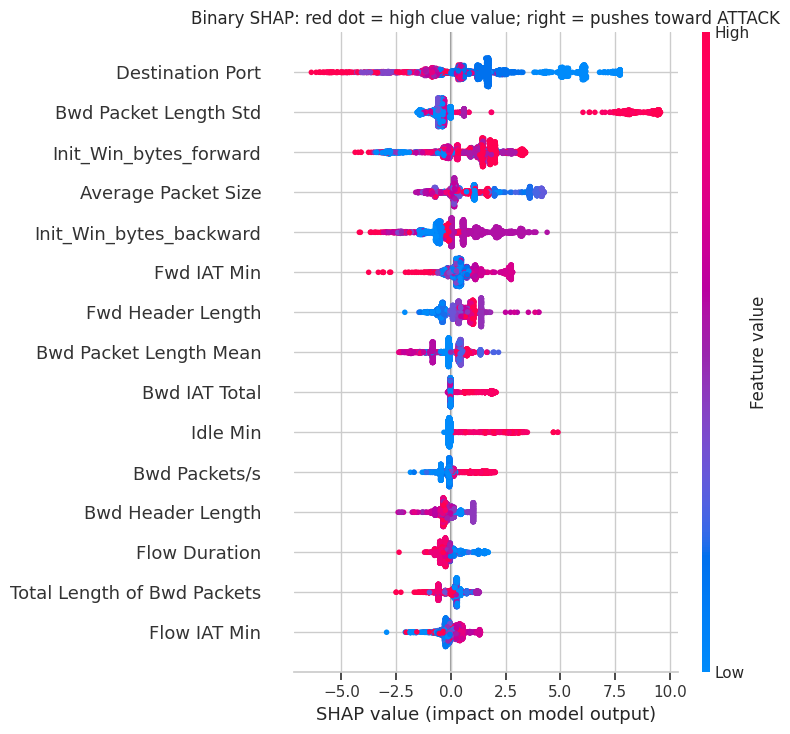

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/08_shap_binary_bar.png


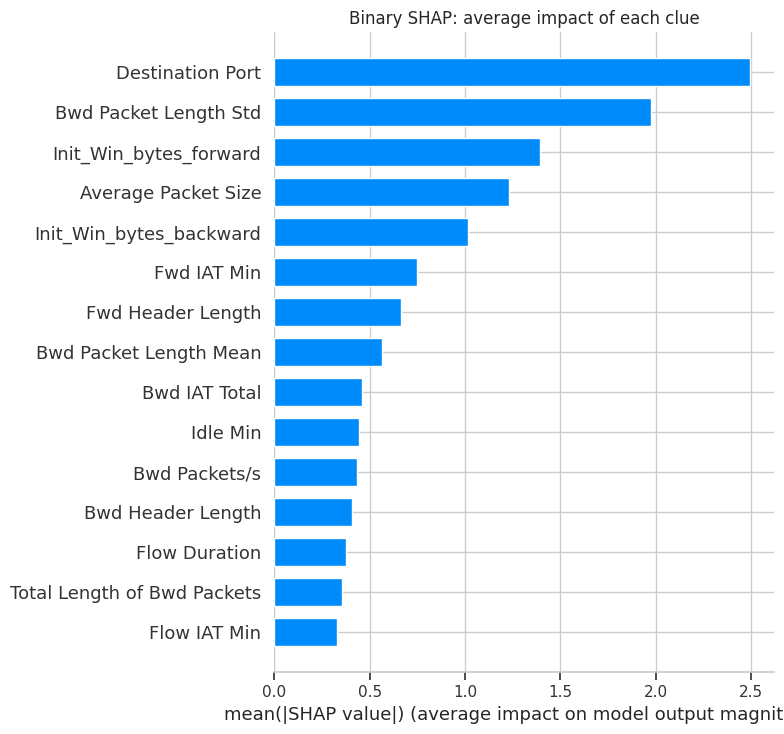

Agreement between SHAP ranking and gain ranking (Spearman): 0.67
            SHAP top 10                 gain top 10
       Destination Port       Bwd Packet Length Std
  Bwd Packet Length Std         Average Packet Size
 Init_Win_bytes_forward           Bwd Header Length
    Average Packet Size                Flow Bytes/s
Init_Win_bytes_backward Total Length of Bwd Packets
            Fwd IAT Min                  Active Std
      Fwd Header Length                 Fwd IAT Max
 Bwd Packet Length Mean            Destination Port
          Bwd IAT Total           Fwd Header Length
               Idle Min                 Fwd IAT Min
[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/08_shap_binary_importance.csv


In [4]:
expl_b = shap.TreeExplainer(xgb_bin)
sv_b = expl_b.shap_values(X_s)

shap.summary_plot(sv_b, X_s, max_display=15, show=False)
plt.title("Binary SHAP: red dot = high clue value; right = pushes toward ATTACK")
save_fig("08_shap_binary_beeswarm")
plt.show()

shap.summary_plot(sv_b, X_s, plot_type="bar", max_display=15, show=False)
plt.title("Binary SHAP: average impact of each clue")
save_fig("08_shap_binary_bar")
plt.show()

shap_bin = pd.Series(np.abs(sv_b).mean(axis=0), index=FEATURES).sort_values(ascending=False)
rho = spearmanr(shap_bin[FEATURES], imp_bin[FEATURES]).correlation
print(f"Agreement between SHAP ranking and gain ranking (Spearman): {rho:.2f}")
cmp = pd.DataFrame({"SHAP top 10": shap_bin.head(10).index,
                    "gain top 10": imp_bin.sort_values(ascending=False).head(10).index})
print(cmp.to_string(index=False))
save_table(shap_bin.round(5).to_frame("mean_abs_shap"), "08_shap_binary_importance")

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/08_shap_multiclass_bar.png


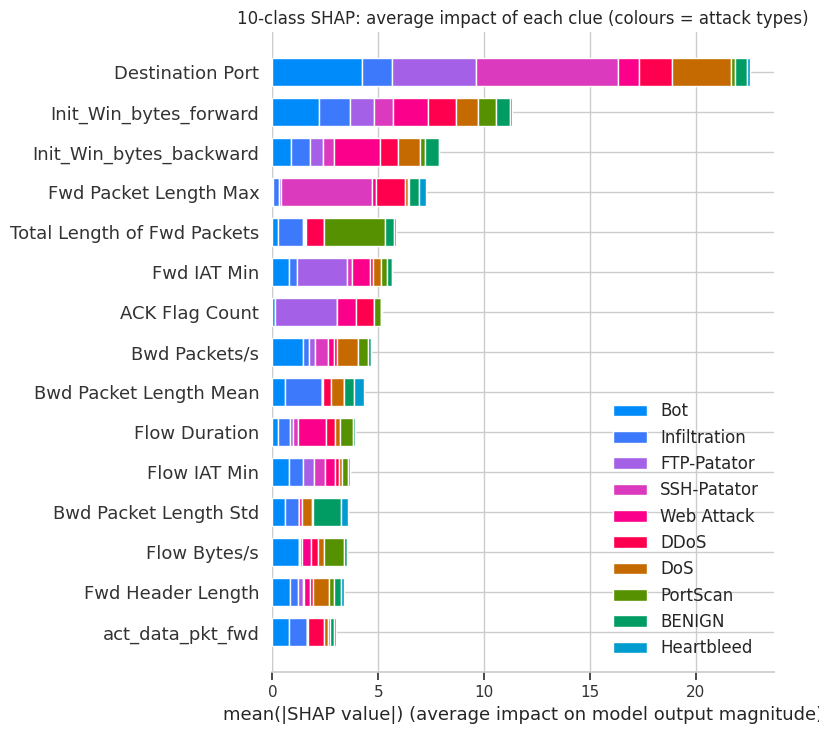

       class                                 #1                            #2                             #3                                 #4                                 #5
      BENIGN       Bwd Packet Length Std (1.34) Init_Win_bytes_forward (0.67)     Average Packet Size (0.64)     Init_Win_bytes_backward (0.64)           Bwd Header Length (0.63)
         Bot            Destination Port (4.25) Init_Win_bytes_forward (2.22)           Bwd Packets/s (1.44)                Flow Bytes/s (1.24) Total Length of Bwd Packets (0.99)
        DDoS            Destination Port (1.56)  Fwd Packet Length Max (1.40)  Init_Win_bytes_forward (1.30) Total Length of Fwd Packets (0.87)              ACK Flag Count (0.83)
         DoS            Destination Port (2.79) Init_Win_bytes_forward (1.07) Init_Win_bytes_backward (1.05)               Bwd Packets/s (1.03)           Fwd Header Length (0.78)
 FTP-Patator            Destination Port (3.96)         ACK Flag Count (2.93)             Fwd IAT Min (2.

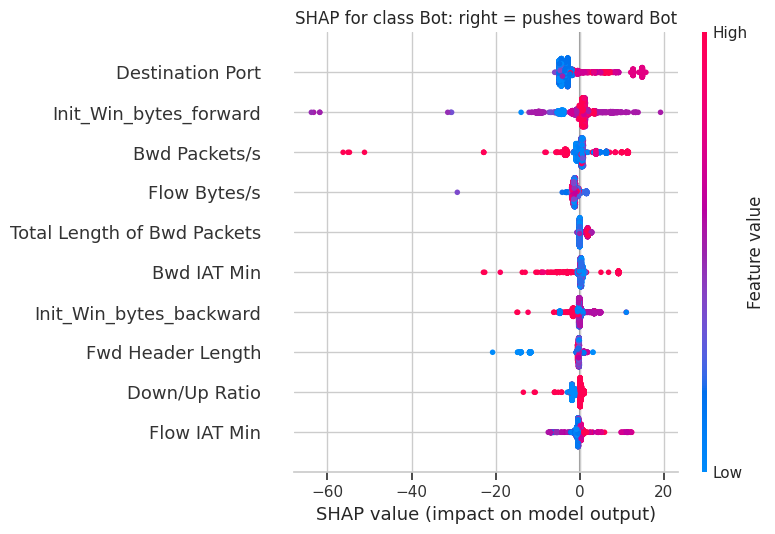

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/08_shap_multiclass_PortScan.png


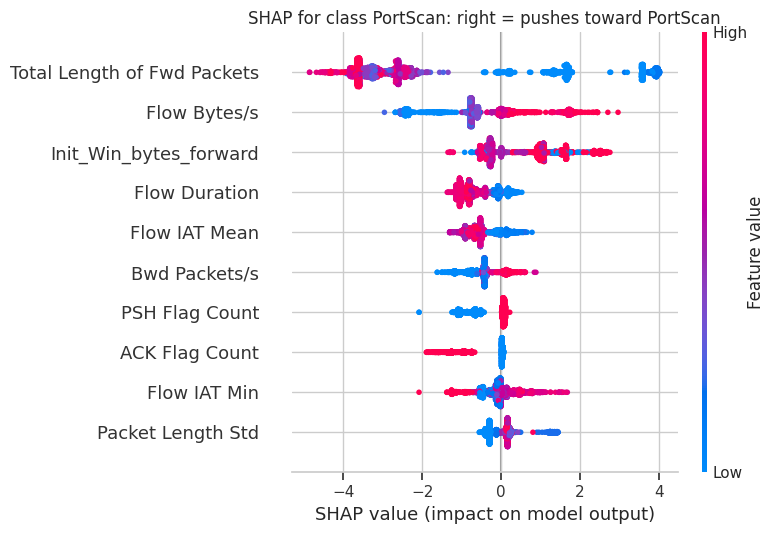

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/08_shap_multiclass_Web_Attack.png


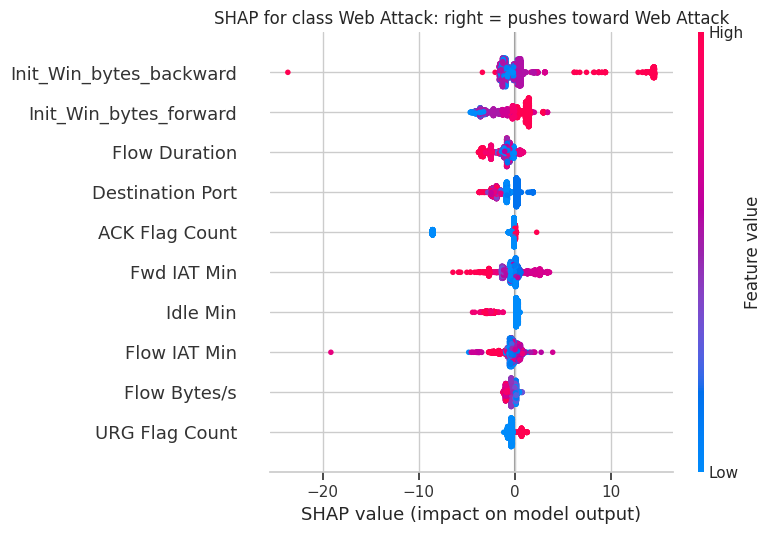

In [5]:
expl_m = shap.TreeExplainer(xgb_multi)
sv_m = expl_m.shap_values(X_s)
sv_list = sv_m if isinstance(sv_m, list) else [sv_m[:, :, k] for k in range(sv_m.shape[2])]

shap.summary_plot(sv_list, X_s, plot_type="bar", class_names=class_names, max_display=15, show=False)
plt.title("10-class SHAP: average impact of each clue (colours = attack types)")
save_fig("08_shap_multiclass_bar")
plt.show()

# top 5 clues for each attack type
rows = []
for k, name in enumerate(class_names):
    s = pd.Series(np.abs(sv_list[k]).mean(axis=0), index=FEATURES).sort_values(ascending=False).head(5)
    rows.append({"class": name, **{f"#{j+1}": f"{f} ({v:.2f})" for j, (f, v) in enumerate(s.items())}})
top5 = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)
print(top5.to_string(index=False))
save_table(top5, "08_shap_top5_per_class", index=False)

for name in ["Bot", "PortScan", "Web Attack"]:
    k = label_mapping[name]
    shap.summary_plot(sv_list[k], X_s, max_display=10, show=False)
    plt.title(f"SHAP for class {name}: right = pushes toward {name}")
    save_fig(f"08_shap_multiclass_{name.replace(' ', '_')}")
    plt.show()

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/08_shap_local_caught_attack.png


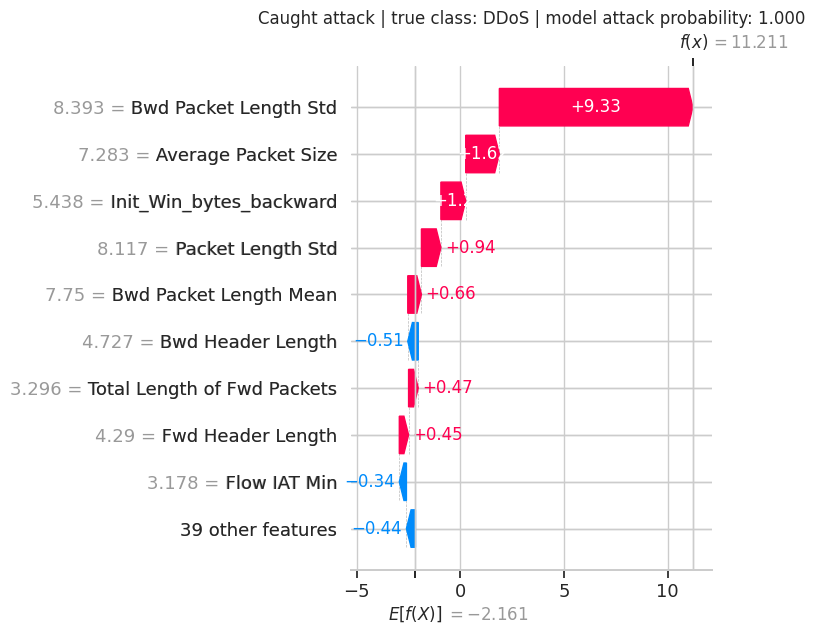

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/08_shap_local_false_alarm.png


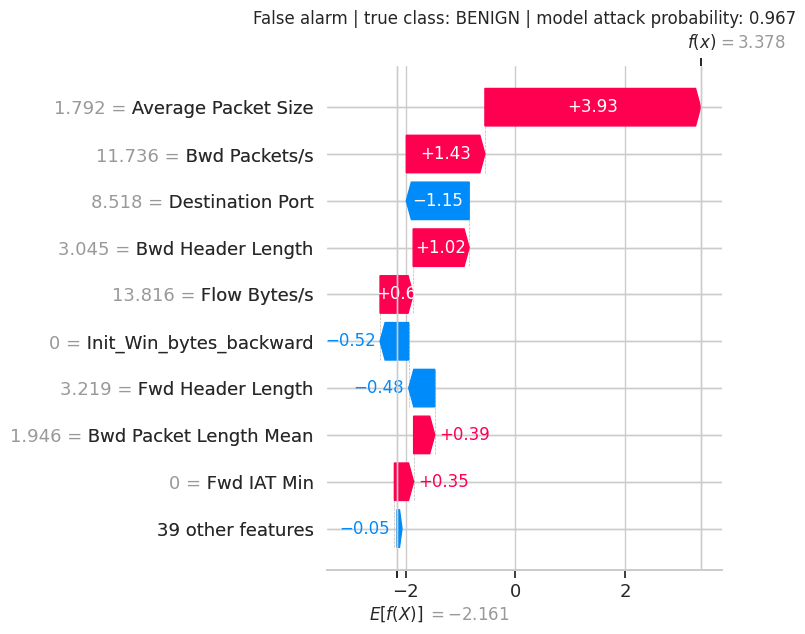

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/08_shap_local_missed_attack.png


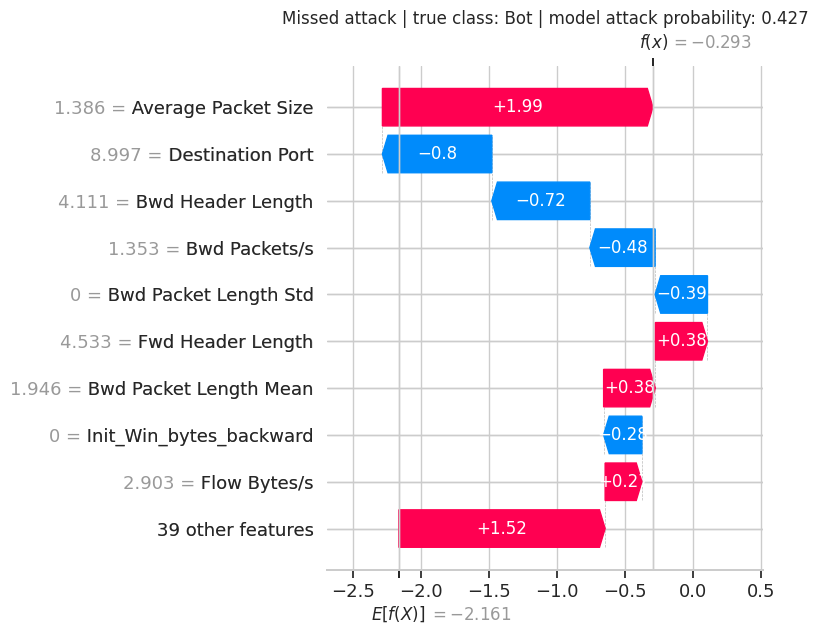

In [6]:
sv_loc = expl_b.shap_values(X_loc)
ev = float(np.ravel(expl_b.expected_value)[0])

for j, name in enumerate(local.keys()):
    exp = shap.Explanation(values=sv_loc[j], base_values=ev,
                           data=X_loc.iloc[j].values, feature_names=FEATURES)
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.title(f"{name} | true class: {loc_true[j]} | model attack probability: {loc_prob[j]:.3f}")
    save_fig(f"08_shap_local_{name.replace(' ', '_').lower()}")
    plt.show()

In [7]:
for p in sorted(TABLE_DIR.glob("08_*")) + sorted(FIG_DIR.glob("08_*")):
    print(p.name)

08_gain_importance.csv
08_shap_binary_importance.csv
08_shap_top5_per_class.csv
08_gain_importance.png
08_shap_binary_bar.png
08_shap_binary_beeswarm.png
08_shap_local_caught_attack.png
08_shap_local_false_alarm.png
08_shap_local_missed_attack.png
08_shap_multiclass_Bot.png
08_shap_multiclass_PortScan.png
08_shap_multiclass_Web_Attack.png
08_shap_multiclass_bar.png
